In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

In [ ]:
#a)

def matriz_diferencias(n):

    filas = []

    # Diferencias horizontales
    # Xi,j+1 - Xi,j
    for i in range(n):
        for j in range(n - 1):

            fila = np.zeros(n**2)

            k = i * n + j

            fila[k] = -1
            fila[k + 1] = 1

            filas.append(fila)

    # Diferencias verticales
    # Xi+1,j - Xi,j
    for i in range(n - 1):
        for j in range(n):

            fila = np.zeros(n**2)

            k = i * n + j

            fila[k] = -1
            fila[k + n] = 1

            filas.append(fila)

    D = np.array(filas)

    return D


D = matriz_diferencias(8)

print("Dimensiones de D:", D.shape)

for fila in D:
    assert np.sum(fila == -1) == 1
    assert np.sum(fila == 1) == 1

print("Todas las filas tienen exactamente un -1 y un 1")

Dimensiones de D: (112, 64)
Todas las filas tienen exactamente un -1 y un 1


In [8]:
#b)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_fantoma = X_fantoma.reshape(-1)
n = 8

x_constante = np.ones(n**2)

Dx_constante = D @ x_constante

print("D @ x_constante =")
print(Dx_constante)

print("Norma de D @ x_constante:", np.linalg.norm(Dx_constante))

Dx_fantoma = D @ x_fantoma

print("Norma de D @ x_fantoma:", np.linalg.norm(Dx_fantoma))

D @ x_constante =
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Norma de D @ x_constante: 0.0
Norma de D @ x_fantoma: 2.7055498516937364


Para una imagen constante, todas las diferencias entre pixeles vecinos son cero, por lo tanto D x_constante = 0. En cambio, el fantoma tiene cambios de intensidad entre pixeles, por eso D x_fantoma no es cero y su norma es positiva.


c)
J_sigma,lambda(x) = 1/2 ( ||A7x - b_sigma||^2 + lambda ||Dx||^2 )

La primera parte, ||A7x - b_sigma||^2, mide qué tan bien la imagen x reproduce las mediciones. Si este valor es chico, las mediciones generadas por x se parecen mucho a las mediciones ruidosas b_sigma.

La segunda parte, ||Dx||^2, mide cuánto cambian los valores entre pixeles vecinos. Si es chico, la imagen es más suave; si es grande, hay muchos cambios entre pixeles vecinos.

Lambda controla cuánto importa la suavidad. Si lambda = 0, no se penalizan los cambios entre pixeles. Si lambda aumenta, el método favorece imágenes más suaves, aunque puede perder detalles.     TP_Metodos_Computacionales

Para copiar y pegar en texto normal:

La primera parte de J mide qué tan bien la imagen reconstruida reproduce las mediciones. La norma de Dx mide cuánto cambian los valores entre pixeles vecinos, por lo que indica qué tan suave es la imagen. Lambda controla la importancia de esa suavidad: cuanto mayor es lambda, más se penalizan las diferencias entre pixeles vecinos y más suave queda la reconstrucción.

In [11]:
#d)

#ARMO A7
def mascara_rayo(n, direccion, s):
    res =  np.zeros((n, n))
    for i in range(n) :
        for j in range(n):
            if (direccion[0]*i + direccion[1]*j) == s:
                res[i,j] =1
    return res
            

def matriz_proyeccion(n, direcciones):
    filas_A = []
    for direccion in direcciones:
        valoresdes=[]
        for i in range(n):
            for j in range(n):
                s = direccion[0]*i + direccion[1]*j
                valoresdes.append(s)
    
        ssinrepetir = []

        for k in valoresdes:
            if k not in ssinrepetir:
                ssinrepetir.append(k)        

        ssinrepetir.sort()

        for s in ssinrepetir:
            fila_s =mascara_rayo(n, direccion, s)
            filas_A.append(fila_s.reshape(-1))
           
    A=np.array(filas_A)
    return A
d7 = [(1,0), (0,1), (1,1), (1, -1), (2,1),(1,2),(3,1)]
A7= matriz_proyeccion(8, d7)

b7 = A7 @ x_fantoma

def generar_mediciones(A, x):
    return A @ x

b7 = generar_mediciones(A7, x_fantoma)

np.random.seed(42)
z = np.random.randn(len(b7))

escala = np.sqrt(np.mean(b7**2))

sigmas = [0, 0.10, 0.20]

b_ruidosos = {}

for sigma in sigmas:
    b_sigma = b7 + sigma * escala * z
    b_ruidosos[sigma] = b_sigma

print("Mediciones generadas para:")
for sigma in sigmas:
    print("sigma =", sigma)

Mediciones generadas para:
sigma = 0
sigma = 0.1
sigma = 0.2


In [12]:
#e)
lambdas = [0, 0.1, 0.3, 1]

reconstrucciones = {}

def J(x, b_sigma, lamb):
    termino_mediciones = np.linalg.norm(A7 @ x - b_sigma)**2
    termino_suavidad = lamb * np.linalg.norm(D @ x)**2

    return 0.5 * (termino_mediciones + termino_suavidad)


def gradJ(x, b_sigma, lamb):
    return (
        A7.T @ (A7 @ x - b_sigma)
        + lamb * D.T @ D @ x
    )


for sigma in sigmas:

    b_sigma = b_ruidosos[sigma]

    for lamb in lambdas:

        x = np.zeros(64)

        # Hessiana de J
        H = A7.T @ A7 + lamb * D.T @ D

        # mayor autovalor
        mu_max = np.max(np.linalg.eigvalsh(H))

        # tasa estable
        alfa = 1 / mu_max

        # gradiente descendiente
        for t in range(1000):
            grad = gradJ(x, b_sigma, lamb)

            x = x - alfa * grad

        reconstrucciones[(sigma, lamb)] = x

In [13]:
#f)
reconstrucciones = {}

def J(x, b_sigma, lamb):
    termino_mediciones = np.linalg.norm(A7 @ x - b_sigma)**2
    termino_suavidad = lamb * np.linalg.norm(D @ x)**2
    return 0.5 * (termino_mediciones + termino_suavidad)


def gradJ(x, b_sigma, lamb):
    return (
        A7.T @ (A7 @ x - b_sigma)
        + lamb * D.T @ D @ x
    )


max_iter = 5000
tolerancia = 1e-6

for sigma in sigmas:

    b_sigma = b_ruidosos[sigma]

    for lamb in lambdas:

        x = np.zeros(64)

        H = A7.T @ A7 + lamb * D.T @ D

        autovalores = np.linalg.eigvalsh(H)
        mu_max = np.max(autovalores)

        alfa = 1 / mu_max

        costos = []

        for t in range(max_iter):

            grad = gradJ(x, b_sigma, lamb)

            costo = J(x, b_sigma, lamb)

            costos.append(costo)

            if np.linalg.norm(grad) < tolerancia:
                break

            x = x - alfa * grad

        reconstrucciones[(sigma, lamb)] = x

        print(
            "sigma =", sigma,
            "lambda =", lamb,
            "alfa =", alfa,
            "iteraciones =", t + 1,
            "costo final =", costos[-1]
        )

sigma = 0 lambda = 0 alfa = 0.027424756403856825 iteraciones = 755 costo final = 9.61222742567542e-13
sigma = 0 lambda = 0.1 alfa = 0.027423790068239733 iteraciones = 490 costo final = 0.3431982758022053
sigma = 0 lambda = 0.3 alfa = 0.027421835112255936 iteraciones = 296 costo final = 0.9289498434076594
sigma = 0 lambda = 1 alfa = 0.02741473798424808 iteraciones = 135 costo final = 2.425971788673944
sigma = 0.1 lambda = 0 alfa = 0.027424756403856825 iteraciones = 862 costo final = 0.23361772735654374
sigma = 0.1 lambda = 0.1 alfa = 0.027423790068239733 iteraciones = 551 costo final = 0.6122341634227391
sigma = 0.1 lambda = 0.3 alfa = 0.027421835112255936 iteraciones = 327 costo final = 1.232975456931574
sigma = 0.1 lambda = 1 alfa = 0.02741473798424808 iteraciones = 146 costo final = 2.7700587161109707
sigma = 0.2 lambda = 0 alfa = 0.027424756403856825 iteraciones = 903 costo final = 0.9344709094232612
sigma = 0.2 lambda = 0.1 alfa = 0.027423790068239733 iteraciones = 577 costo final 

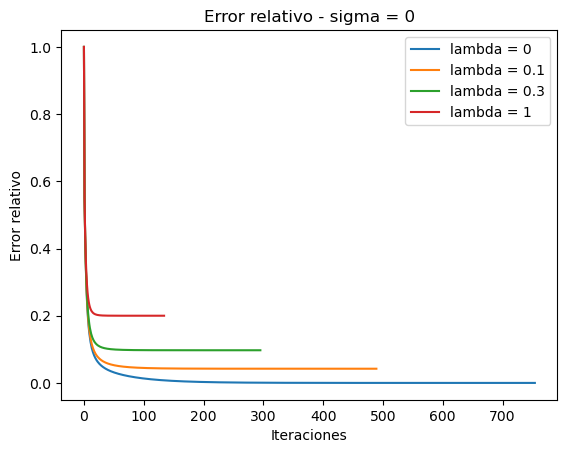

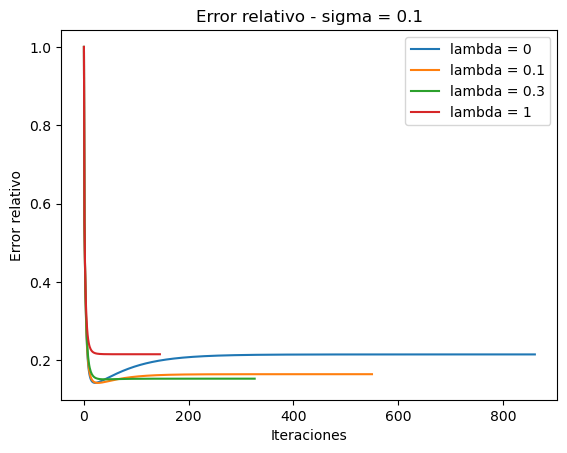

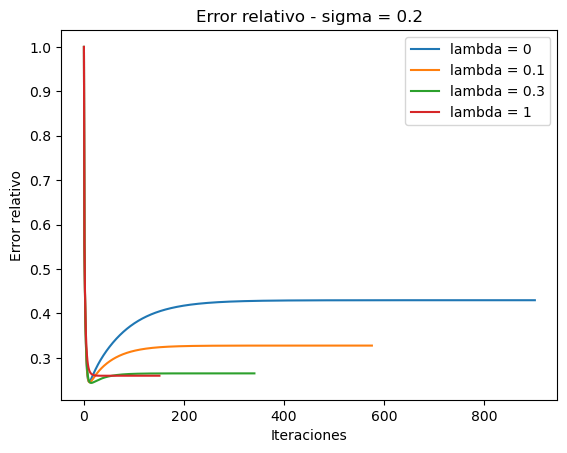

In [14]:
#g)

errores_por_caso = {}

for sigma in sigmas:

    b_sigma = b_ruidosos[sigma]

    for lamb in lambdas:

        x = np.zeros(64)

        H = A7.T @ A7 + lamb * D.T @ D

        mu_max = np.max(np.linalg.eigvalsh(H))

        alfa = 1 / mu_max

        errores = []

        for t in range(max_iter):

            grad = gradJ(x, b_sigma, lamb)

            error_relativo = (
                np.linalg.norm(x - x_fantoma)
                / np.linalg.norm(x_fantoma)
            )

            errores.append(error_relativo)

            if np.linalg.norm(grad) < tolerancia:
                break

            x = x - alfa * grad

        errores_por_caso[(sigma, lamb)] = errores


for sigma in sigmas:

    plt.figure()

    for lamb in lambdas:

        errores = errores_por_caso[(sigma, lamb)]

        plt.plot(
            range(len(errores)),
            errores,
            label=f"lambda = {lamb}"
        )

    plt.title(f"Error relativo - sigma = {sigma}")
    plt.xlabel("Iteraciones")
    plt.ylabel("Error relativo")
    plt.legend()
    plt.show()

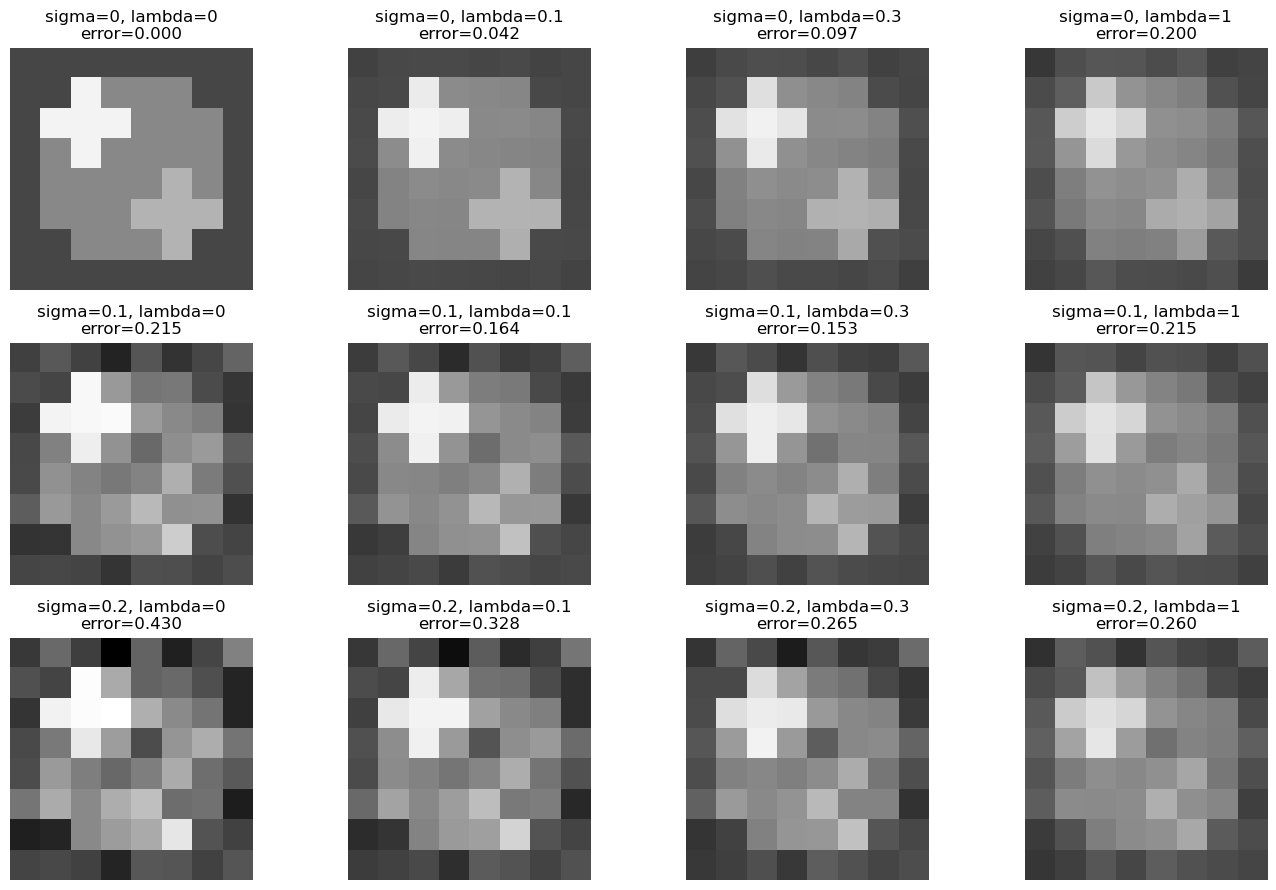

In [15]:
#h)
# calcular escala de color comun
todos_los_valores = []

for sigma in sigmas:
    for lamb in lambdas:
        x = reconstrucciones[(sigma, lamb)]
        todos_los_valores.extend(x)

vmin = np.min(todos_los_valores)
vmax = np.max(todos_los_valores)


fig, axes = plt.subplots(
    len(sigmas),
    len(lambdas),
    figsize=(14, 9)
)

for i, sigma in enumerate(sigmas):

    for j, lamb in enumerate(lambdas):

        x = reconstrucciones[(sigma, lamb)]

        X = x.reshape(8, 8)

        error_relativo = (
            np.linalg.norm(x - x_fantoma)
            / np.linalg.norm(x_fantoma)
        )

        axes[i, j].imshow(
            X,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        axes[i, j].set_title(
            f"sigma={sigma}, lambda={lamb}\nerror={error_relativo:.3f}"
        )

        axes[i, j].axis("off")


plt.tight_layout()
plt.show()

In [16]:
#i)
tabla_resultados = []

for sigma in sigmas:

    b_sigma = b_ruidosos[sigma]

    for lamb in lambdas:

        x = reconstrucciones[(sigma, lamb)]

        error_relativo = (
            np.linalg.norm(x - x_fantoma)
            / np.linalg.norm(x_fantoma)
        )

        residuo = A7 @ x - b_sigma
        norma_residuo = np.linalg.norm(residuo)

        tabla_resultados.append([
            sigma,
            lamb,
            error_relativo,
            norma_residuo
        ])


print("sigma | lambda | error relativo | norma residuo")

for fila in tabla_resultados:
    print(fila)


# buscar el mejor lambda para cada sigma

for sigma in sigmas:

    mejor_lambda = None
    menor_error = np.inf

    for lamb in lambdas:

        x = reconstrucciones[(sigma, lamb)]

        error_relativo = (
            np.linalg.norm(x - x_fantoma)
            / np.linalg.norm(x_fantoma)
        )

        if error_relativo < menor_error:
            menor_error = error_relativo
            mejor_lambda = lamb

    print(
        "sigma =", sigma,
        "mejor lambda =", mejor_lambda,
        "menor error =", menor_error
    )

sigma | lambda | error relativo | norma residuo
[0, 0, 7.597549925369375e-07, 1.3865228036837635e-06]
[0, 0.1, 0.0422709870477756, 0.20083429650798867]
[0, 0.3, 0.09722417497851736, 0.5040036457294776]
[0, 1, 0.19999233302848188, 1.1594322964730235]
[0.1, 0, 0.21488015891978987, 0.6835462345102103]
[0.1, 0.1, 0.16438124499338214, 0.7259941408123909]
[0.1, 0.3, 0.1529634160389635, 0.8882783116762142]
[0.1, 1, 0.21531745320546025, 1.4095455654391862]
[0.2, 0, 0.4297607786967041, 1.3670924690182893]
[0.2, 0.1, 0.32764116189833314, 1.4086591811357916]
[0.2, 0.3, 0.2650635799187117, 1.5459324364673928]
[0.2, 1, 0.2598040062223461, 1.9831995039855501]
sigma = 0 mejor lambda = 0 menor error = 7.597549925369375e-07
sigma = 0.1 mejor lambda = 0.3 menor error = 0.1529634160389635
sigma = 0.2 mejor lambda = 1 menor error = 0.2598040062223461


j)

Para sigma = 0, la regularización no mejora la reconstrucción. El menor error se obtiene con lambda = 0, porque al no haber ruido no hace falta suavizar la imagen y cualquier regularización extra introduce una diferencia respecto de la imagen original.

Para sigma = 0.1, la regularización sí mejora la reconstrucción. El error baja desde aproximadamente 0.215 con lambda = 0 hasta aproximadamente 0.153 con lambda = 0.3. Esto muestra que, cuando hay ruido, penalizar las diferencias entre píxeles vecinos ayuda a recuperar una imagen más cercana al fantoma.

Para sigma = 0.2, el mejor resultado se obtiene con lambda = 1, con un error de aproximadamente 0.260, menor que el error de aproximadamente 0.430 obtenido sin regularización. Esto indica que, al aumentar el ruido, conviene aumentar también la intensidad de la regularización.

En general, cuanto mayor es el ruido, mayor tiende a ser el valor de lambda más conveniente. Sin embargo, una regularización demasiado grande puede suavizar en exceso la imagen, borrar detalles y hacer que el error vuelva a aumentar. En nuestros resultados esto se ve, por ejemplo, para sigma = 0.1, donde lambda = 1 da un error mayor que lambda = 0.3.